In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import nflreadpy as nfl

# Define the years to import
yrs = range(2016, 2025)

# Play-by-Play Data
pbp_data = nfl.load_pbp(yrs)

# Participation Data
participation_data = nfl.load_participation(yrs)

# Merge participation to pbp data
pbp_data = pbp_data.join(participation_data, left_on=['game_id', 'play_id'], right_on=['nflverse_game_id', 'play_id'], how='left')

pbp_data = pbp_data.to_pandas()

# Create Features

In [2]:
import numpy as np
import pandas as pd
import re

def feature_engineering(pbp_data):
    # 1. Define data
    df = pbp_data[['play_type', 'offense_formation', 'defenders_in_box', 'ydstogo', 'half_seconds_remaining', 'wp', 'ep', 'week', 'down', 'run_gap',
                   'defense_personnel', 'offense_personnel', 'number_of_pass_rushers', 'defense_man_zone_type', 'defense_coverage_type', 'yardline_100', 'xpass', 'play_clock',
                   'temp', 'wind', 'roof', 'surface', 'posteam_timeouts_remaining', 'defteam_timeouts_remaining', 'shotgun', 'no_huddle', 'home_team', 'posteam', 'defteam',
                   'qb_dropback', 'qb_kneel', 'qb_spike', 'qb_scramble', 'score_differential', 'qtr', 'drive',
                   'game_id', 'play_id', 'epa', 'yards_gained', 'wpa'] # Should not be used in X
                   ].sort_values(['game_id', 'play_id']).copy()

    df = df[df['play_type'].isin(['run','pass'])].copy()

    # Fill NaNs for numerical features that will be used in calculations
    df['number_of_pass_rushers'] = df['number_of_pass_rushers'].fillna(4)
    df['play_clock'] = df['play_clock'].fillna(40) # Assume 40 seconds if missing

    standard_cols = ['play_type', 'defenders_in_box', 'number_of_pass_rushers', 'ydstogo', 'half_seconds_remaining', 'wp', 'ep', 'week', 'down',
                     'yardline_100', 'xpass', 'score_differential', 'qtr', 'drive', 'temp']
    original_standard_cols = standard_cols.copy()

    # --- 2. Personnel counts and Ratios (Enhanced) ---
    df['rb_count'] = df['offense_personnel'].str.extract(r'(\d+)\s*RB').astype(float)
    df['wr_count'] = df['offense_personnel'].str.extract(r'(\d+)\s*WR').astype(float)
    df['te_count'] = df['offense_personnel'].str.extract(r'(\d+)\s*TE').astype(float)
    df['db_count'] = df['defense_personnel'].str.extract(r'(\d+)\s*DB').astype(float)
    df['lb_count'] = df['defense_personnel'].str.extract(r'(\d+)\s*LB').astype(float)
    df['dl_count'] = df['defense_personnel'].str.extract(r'(\d+)\s*DL').astype(float)
    
    # Fill personnel counts (usually 0 if not explicitly listed)
    personnel_fill_cols = ['rb_count', 'wr_count', 'te_count', 'db_count', 'lb_count', 'dl_count']
    for col in personnel_fill_cols:
        df[col] = df[col].fillna(0)


    df['wr_db_diff'] = df['wr_count'] - df['db_count']
    df['rb_lb_diff'] = df['rb_count'] - df['lb_count']
    df['blockers'] = 5 + df['te_count'] + df['rb_count'] 
    df['pressure_ratio'] = df['number_of_pass_rushers'] / (df['blockers'] + 1e-6)
    df['box_minus_rushers'] = df['defenders_in_box'] - df['number_of_pass_rushers']
    df['box_advantage'] = df['box_minus_rushers'] / (df['number_of_pass_rushers'] + 1e-6)
    df['defensive_back_density'] = df['db_count'] / (df['defenders_in_box'] + 1e-6)
    df['front_density'] = (df['dl_count'] + df['lb_count']) / (df['defenders_in_box'] + 1e-6)
    df['receiver_db_ratio'] = df['wr_count'] / (df['db_count'] + 1e-6)
    df['xpass_receivers'] = (df['wr_count'] + df['te_count']) * df['xpass']
    df['skill_vs_coverage'] = (df['rb_count'] + df['wr_count'] + df['te_count']) / (df['lb_count'] + df['db_count'] + 1e-6)
    df['box_skill_pressure'] = df['defenders_in_box'] / (df['rb_count'] + df['wr_count'] + 1e-6)
    df['coverage_complexity'] = df['db_count'] / (df['lb_count'] + 1e-6)
    df['blitz_indicator'] = df['number_of_pass_rushers'] - df['dl_count']
    df['rush_position_diversity'] = (df['lb_count'] + df['db_count']) / (df['dl_count'] + 1e-6)
    df['skill_players_total'] = df['rb_count'] + df['wr_count'] + df['te_count']
    df['receiver_blocker_balance'] = (df['wr_count'] + df['te_count']) / (df['rb_count'] + df['te_count'] + 5)
    df['blocker_to_rusher_ratio'] = df['blockers'] / (df['number_of_pass_rushers'] + 1e-6)
    df['pass_block_stress'] = df['number_of_pass_rushers'] - df['blockers']
    df['pass_advantage'] = (df['wr_count'] + df['te_count']) - df['db_count']
    df['defensive_front_leverage'] = df['dl_count'] - df['te_count']
    df['pressure_on_late_downs'] = df['pressure_ratio'] * (df['down'] >= 3).astype(int)
    df['o_formation_reuse'] = (df.groupby(['game_id', 'offense_formation']).cumcount())
    df['d_coverage_reuse'] = (df.groupby(['game_id', 'defense_coverage_type']).cumcount())

    personnel_cols = ['rb_count', 'wr_count', 'te_count', 'db_count', 'lb_count', 'dl_count',
                      'box_minus_rushers', 'box_advantage', 'defensive_back_density', 'receiver_db_ratio', 'xpass_receivers',
                      'front_density', 'pressure_ratio', 'blockers', 'wr_db_diff', 'rb_lb_diff', 'skill_vs_coverage',
                      'box_skill_pressure', 'coverage_complexity', 'blitz_indicator', 'rush_position_diversity',
                      'receiver_blocker_balance', 'blocker_to_rusher_ratio',
                      'pass_advantage', 'defensive_front_leverage', 'pressure_on_late_downs', 'o_formation_reuse', 'd_coverage_reuse'
                      ]

    # --- 3. Core features (Original + Deep Time/Non-Linear Transforms) ---
    df['log_ydstogo'] = np.log1p(df['ydstogo'])
    df['log_yardline'] = np.log1p(df['yardline_100'])
    df['garbage_time'] = ((df['wp'] <= 0.10) | (df['wp'] >= 0.90)).astype(int)
    df['two_min_warn'] = (df['half_seconds_remaining'] <= 120).astype(int)
    df['win_formation'] = ((df['wp'] >= 0.75).astype(int) & (df['half_seconds_remaining'] <= 120).astype(int))
    df['dist_down'] = df['down'] * df['ydstogo']
    df['home_field'] = (df['posteam'] == df['home_team']).astype(int)
    df['timeout_diff'] = df['posteam_timeouts_remaining'] - df['defteam_timeouts_remaining']
    df['yardline_wp'] = df['yardline_100'] * df['wp']
    df['score_diff_qtr'] = df['score_differential'] * df['qtr']
    df['score_diff_drive'] = df['score_differential'] * df['drive']
    df['epa_leverage'] = df['wp'] * (100 - df['yardline_100']) / 100
    df['critical_down'] = ((df['down'] >= 3) & (df['ydstogo'] > 5)).astype(int)
    df['crunch_time'] = ((df['qtr'] == 4) & (df['wp'] <= 0.33)).astype(int)
    df['prev_yards_gain'] = df.groupby('game_id')['yards_gained'].shift(1)
    df['overreaction'] = (df['prev_yards_gain'] >= 10).astype(int)
    df['soft_defense'] = ((df['score_differential'] >= 7) & (df['yardline_100'] >= 45) & (df['half_seconds_remaining'] <= 120)).astype(int)
    df['yardline_per_sec'] = df['yardline_100'] / (df['half_seconds_remaining'] + 1e-6)
    df['rolling_pass_plays'] = df.groupby('game_id')['play_type'].transform(lambda x: (x == 'pass').rolling(window=3, min_periods=1).sum())
    df['pass_over_expected'] = ((df['play_type'] == 'pass').astype(int) - df['xpass']).abs()
    df['rolling_pass_over_expected'] = df.groupby('posteam')['pass_over_expected'].transform(lambda x: x.rolling(window=120, min_periods=1).mean())

    # --- NEW: Deep Time and Play Clock Features ---
    df['time_pressure_quad'] = (df['half_seconds_remaining']**2) / (df['yardline_100'] + 1e-6)
    
    # Define Field Zones (Contextual Geometry) 
    def get_field_zone(yardline):
        if yardline <= 10: return 'Goal_Line'
        if yardline <= 20: return 'Red_Zone'
        if yardline >= 80: return 'Opponent_Half'
        if yardline >= 40 and yardline <= 60: return 'Midfield'
        return 'Own_Territory'
    
    df['field_zone_category'] = df['yardline_100'].apply(get_field_zone)

    core_cols = ['log_ydstogo', 'log_yardline', 'garbage_time', 'two_min_warn',
                 'win_formation', 'dist_down', 'home_field', 'timeout_diff', 'yardline_wp',
                 'score_diff_qtr', 'score_diff_drive', 'epa_leverage', 'critical_down',
                 'crunch_time', 'overreaction', 'prev_yards_gain', 'soft_defense', 'yardline_per_sec', 
                 'rolling_pass_plays', 'time_pressure_quad', 'rolling_pass_over_expected'
                 ]

    # --- 4. Situational Interaction Features (NEW GROUP) ---
    df['two_min_red_zone_int'] = df['two_min_warn'] * (df['field_zone_category'] == 'Red_Zone').astype(int)
    df['fourth_down_leverage'] = (df['down'] == 4).astype(int) * df['epa_leverage']
    df['run_gap_defenders_int'] = df['defenders_in_box'] * (df['run_gap'].isin(['end', 'guard', 'tackle'])).astype(int) # Interior vs. Box
    df['long_down_midfield'] = ((df['down'] >= 3) & (df['ydstogo'] >= 10) & (df['field_zone_category'] == 'Midfield')).astype(int)
    
    situational_cols = ['two_min_red_zone_int', 'fourth_down_leverage', 'run_gap_defenders_int', 'long_down_midfield']

    # Drop original columns used for calculations
    df = df.drop(columns=['home_team', 'offense_personnel', 'defense_personnel'], axis=1)

    # Step 5.1: Define categorical columns before dummy expansion
    # 'field_zone_category' and 'defteam' are added
    categorical_columns_raw = ['play_type', 'offense_formation', 'run_gap', 'defense_man_zone_type',
                               'defense_coverage_type', 'roof', 'surface', 'field_zone_category'
                               ]

    # Step 5.2: One-hot encode and collect dummy column names
    dummy_col_mapping = {}
    for col in categorical_columns_raw:
        dummies = pd.get_dummies(df[col], prefix=col, drop_first=True, dummy_na=False) # Keep NaNs out of dummy creation
        dummy_col_mapping[col] = list(dummies.columns)
        df = pd.concat([df, dummies], axis=1)

    # Remove original categorical columns, except 'posteam' (needed for rolling)
    df.drop(columns=categorical_columns_raw, inplace=True)

    # Step 5.3: Define the new categorical_cols group
    categorical_cols = []
    for col in categorical_columns_raw:
        categorical_cols.extend(dummy_col_mapping[col])

    # Step 6: Rebuild standard_cols (numerical/binary columns only)
    standard_cols = []
    for col in original_standard_cols:
        if col not in categorical_columns_raw and col in df.columns:
            standard_cols.append(col)

    # Sanity check: Ensure no overlap
    assert len(set(standard_cols).intersection(categorical_cols)) == 0

    # --- 7. Create Rolling Averages (Enhanced with Defteam and Context) ---
    df = df.sort_values(['game_id', 'play_id']).copy() # Re-sort to ensure correct play order

    # Base features for rolling
    rol_cols_base = [col for col in categorical_cols if col.startswith(('play_type', 'offense_formation', 'run_gap', 'defense_man_zone_type',
                               'defense_coverage_type'))] + ['rb_count', 'wr_count', 'te_count', 'db_count', 'lb_count', 'dl_count',
                              'box_minus_rushers', 'box_advantage', 'defensive_back_density', 'receiver_db_ratio', 'xpass_receivers',
                              'front_density', 'pressure_ratio']
    
    rolling_cols = []
    rolling_window = 180

    # 7a. POSTEAM ROLLING (Original)
    df = df.sort_values(['posteam', 'game_id', 'play_id']).copy()
    for col in rol_cols_base:
        df[f'{col}_posteam_avg'] = df.groupby('posteam')[col].transform(lambda x: x.shift(1).rolling(window=rolling_window, min_periods=1).mean())
        rolling_cols.append(f'{col}_posteam_avg')

    # 7b. DEFTEAM ROLLING (NEW: Defensive Tendencies)
    df = df.sort_values(['defteam', 'game_id', 'play_id']).copy()
    
    # Rolling Pass/Run DVOA (Defense Vs. Offense Type)
    df['play_type_pass_dummy'] = (df['play_type_pass'] == 1).astype(int) if 'play_type_pass' in df.columns else (df['play_type_run'] == 0).astype(int)
    df['d_pass_rate_allowed_avg'] = df.groupby('defteam')['play_type_pass_dummy'].transform(lambda x: x.shift(1).rolling(window=120, min_periods=1).mean())
    rolling_cols.extend(['d_pass_rate_allowed_avg'])

    for col in rol_cols_base:
        df[f'{col}_defteam_avg'] = df.groupby('defteam')[col].transform(lambda x: x.shift(1).rolling(window=rolling_window, min_periods=1).mean())
        rolling_cols.append(f'{col}_defteam_avg')

    # Drop team identifiers after rolling calculations
    df = df.drop(columns=['posteam', 'defteam'], axis=1, errors='ignore')

    # Final feature collection: Combine personnel, core, rolling, and new situational features
    all_feature_cols = standard_cols + personnel_cols + core_cols + situational_cols + rolling_cols
    
    # Clean up the returned lists to ensure they only contain columns present in the final df
    final_categorical_cols = [col for col in categorical_cols if col in df.columns]
    final_standard_cols = [col for col in standard_cols if col in df.columns]
    final_core_cols = [col for col in core_cols if col in df.columns]
    final_personnel_cols = [col for col in personnel_cols if col in df.columns]
    final_rolling_cols = [col for col in rolling_cols if col in df.columns]
    
    # Add new situational columns to personnel list for modeling purposes if desired
    final_personnel_cols.extend(situational_cols)
    
    return df, final_categorical_cols, final_standard_cols, final_core_cols, final_personnel_cols, final_rolling_cols

# NOTE: You would call this function after loading your pbp_data
df, categorical_cols, standard_cols, core_cols, personnel_cols, rolling_cols = feature_engineering(pbp_data)
df.head()

,defenders_in_box,ydstogo,half_seconds_remaining,wp,ep,week,down,number_of_pass_rushers,yardline_100,xpass,...,db_count_defteam_avg,lb_count_defteam_avg,dl_count_defteam_avg,box_minus_rushers_defteam_avg,box_advantage_defteam_avg,defensive_back_density_defteam_avg,receiver_db_ratio_defteam_avg,xpass_receivers_defteam_avg,front_density_defteam_avg,pressure_ratio_defteam_avg
1756,7.0,10.0,1607.0,0.493707,0.900791,1,1.0,5.0,74.0,0.429097,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1757,6.0,10.0,1601.0,0.478042,0.336534,1,2.0,4.0,74.0,0.486073,...,5.0,3.000000,3.000000,2.00,0.400000,0.714286,0.6,1.716389,0.857143,0.714286
1758,6.0,10.0,1562.0,0.450740,-0.383642,1,3.0,4.0,74.0,0.973527,...,5.0,3.500000,2.500000,2.00,0.450000,0.773809,0.6,1.830341,0.928571,0.642857
1760,6.0,19.0,1501.0,0.490740,0.628336,1,1.0,3.0,72.0,0.605623,...,5.0,3.666667,2.333333,2.00,0.466667,0.793651,0.6,2.518263,0.952381,0.619048
1761,7.0,10.0,1470.0,0.529993,2.305925,1,1.0,4.0,53.0,0.440557,...,5.0,3.500000,2.500000,2.25,0.600000,0.803571,0.6,2.494321,0.964286,0.571428


# Implement Ensemble Models

In [5]:
# Load models from C:\Users\Jack\Documents\GitHub\FFInsights
import joblib
from sklearn.metrics import mean_squared_error, r2_score, roc_auc_score
import numpy as np

variance_encoder_model = joblib.load(r'C:\Users\Jack\Documents\GitHub\FFInsights\variance_encoder_context_model.pkl')
pressure_model = joblib.load(r'C:\Users\Jack\Documents\GitHub\FFInsights\pressure_context_model.pkl')
time_to_throw_model = joblib.load(r'C:\Users\Jack\Documents\GitHub\FFInsights\time_to_throw_context_model.pkl')
yac_model = joblib.load(r'C:\Users\Jack\Documents\GitHub\FFInsights\yac_context_model.pkl')
rush_model = joblib.load(r'C:\Users\Jack\Documents\GitHub\FFInsights\rush_context_model.pkl')
completion_model = joblib.load(r'C:\Users\Jack\Documents\GitHub\FFInsights\completion_context_model.pkl')
pass_breakup_model = joblib.load(r'C:\Users\Jack\Documents\GitHub\FFInsights\pass_breakup_context_model.pkl')

epa_context_model = joblib.load(r'C:\Users\Jack\Documents\GitHub\FFInsights\epa_context_model.pkl')

# Define a function to predict context-specific features
def predict_context_features(df_slice, model, target_values=None):
    # Handle models trained with older scikit-learn versions
    if hasattr(model, 'feature_names_in_'):
        expected_cols = list(model.feature_names_in_)
    else:
        # Fallback: use n_features_in_ to get the first N columns from df_slice
        n_features = model.n_features_in_
        expected_cols = df_slice.columns[:n_features].tolist()
    
    X = df_slice[expected_cols].copy().replace([np.inf, -np.inf], 0)

    if target_values is not None:
        y_true = pd.Series(target_values).fillna(0)
        if y_true.dtype == 'int64' or y_true.nunique() == 2:
            preds = model.predict_proba(X)[:, 1]
            auc_roc = roc_auc_score(y_true, preds)
            mse = mean_squared_error(y_true, preds)
            print(f"   Validation: MSE: {mse:.4f} | AUC-ROC: {auc_roc:.4f}")
        else:
            preds = model.predict(X)
            r2 = r2_score(y_true, preds)
            mse = mean_squared_error(y_true, preds)
            print(f"   Validation: MSE: {mse:.4f} | R-squared: {r2:.4f}")
    else:
        # Predict without validation
        if hasattr(model, 'predict_proba'):
            preds = model.predict_proba(X)[:, 1]
        else:
            preds = model.predict(X)

    return pd.Series(preds, index=df_slice.index)

# Align pbp_data to df index to avoid unalignable boolean masks
pbp_aligned = pbp_data.reindex(df.index)

# Build mask from the aligned pbp data
mask_pass = pbp_aligned['play_type'].eq('pass')
mask_run = pbp_aligned['play_type'].eq('run')

# Apply with proper masks and aligned indices
print(f'Variance Encoder Prediction:')
y_variance_encoder = pd.Series(df['epa']**2)
df['variance_encoder'] = predict_context_features(df, variance_encoder_model, y_variance_encoder)

print(f'Pressure Prediction:')
y_pressure = np.where(pbp_aligned.loc[mask_pass, 'was_pressure'].fillna(0), 1.0, 0.0)
df.loc[mask_pass, 'pressure_prob'] = predict_context_features(df.loc[mask_pass], pressure_model, y_pressure)

print(f'Time to Throw Prediction:')
y_time_to_throw = pbp_aligned.loc[mask_pass, 'time_to_throw']
df.loc[mask_pass, 'predicted_time_to_throw'] = predict_context_features(df.loc[mask_pass], time_to_throw_model, y_time_to_throw)

print(f'Rushing Yards Prediction:')
y_rush = pbp_aligned.loc[mask_run, 'yards_gained']
df.loc[mask_run, 'predicted_rush_yards'] = predict_context_features(df.loc[mask_run], rush_model, y_rush)

print(f'Yards After Catch Prediction:')
y_yac = pbp_aligned.loc[mask_pass, 'yards_after_catch']
df.loc[mask_pass, 'predicted_yac'] = predict_context_features(df.loc[mask_pass], yac_model, y_yac)

print(f'Completion Prediction:')
y_completion = np.where(pbp_aligned.loc[mask_pass, 'complete_pass'].fillna(0), 1.0, 0.0)
df.loc[mask_pass, 'completion_prob'] = predict_context_features(df.loc[mask_pass], completion_model, y_completion)

print(f'Pass Breakup Prediction:')
y_pass_breakup = pbp_aligned.loc[mask_pass, 'pass_defense_1_player_id'].notna().astype(float)
df.loc[mask_pass, 'pass_breakup_prob'] = predict_context_features(df.loc[mask_pass], pass_breakup_model, y_pass_breakup)

Variance Encoder Prediction:
   Validation: MSE: 24.7429 | R-squared: 0.1495
Pressure Prediction:
   Validation: MSE: 0.2339 | AUC-ROC: 0.6253
Time to Throw Prediction:
   Validation: MSE: 1.4399 | R-squared: 0.0220
Rushing Yards Prediction:
   Validation: MSE: 37.9229 | R-squared: 0.0420
Yards After Catch Prediction:
   Validation: MSE: 33.4727 | R-squared: 0.0269
Completion Prediction:
   Validation: MSE: 0.2392 | AUC-ROC: 0.6224
Pass Breakup Prediction:
   Validation: MSE: 0.2228 | AUC-ROC: 0.5525


In [6]:
df[['variance_encoder', 'pressure_prob', 'predicted_rush_yards', 'predicted_yac', 'completion_prob', 'pass_breakup_prob', 'predicted_time_to_throw']].isnull().sum()

variance_encoder                0
pressure_prob              128258
predicted_rush_yards       181927
predicted_yac              128258
completion_prob            128258
pass_breakup_prob          128258
predicted_time_to_throw    128258
dtype: int64

In [7]:
df[['variance_encoder', 'pressure_prob', 'predicted_rush_yards', 'predicted_yac', 'completion_prob', 'pass_breakup_prob', 'predicted_time_to_throw']].mean()

variance_encoder           2.087067
pressure_prob              0.481442
predicted_rush_yards       4.204817
predicted_yac              3.048101
completion_prob            0.498719
pass_breakup_prob          0.458796
predicted_time_to_throw    2.347705
dtype: float32

In [ ]:
print(f'XGB Prediction:')
y_epa = df['epa'].fillna(0)
mlp_model = joblib.load(r'C:\Users\Jack\Documents\GitHub\FFInsights\epa_context_model.pkl')
cols = ['o_formation_reuse', 'defense_man_zone_type_MAN_COVERAGE', 'defensive_back_density', 'defense_man_zone_type_ZONE_COVERAGE', 'front_density', 'defenders_in_box', 
        'defense_man_zone_type_ZONE_COVERAGE_posteam_avg', 'd_coverage_reuse', 'defense_coverage_type_COVER_3_posteam_avg', 'defense_coverage_type_COVER_3_defteam_avg', 
        'defense_man_zone_type_ZONE_COVERAGE_defteam_avg', 'defense_coverage_type_COVER_1_defteam_avg', 'defense_man_zone_type_MAN_COVERAGE_defteam_avg', 'play_type_run', 
        'down', 'defense_man_zone_type_MAN_COVERAGE_posteam_avg', 'defense_coverage_type_COVER_6_posteam_avg', 'box_skill_pressure', 'completion_prob', 'roof_open', 
        'roof_outdoors', 'defense_coverage_type_COVER_3', 'box_advantage', 'run_gap_defenders_int', 'pressure_prob', 'predicted_yac', 'predicted_rush_yards', 'box_minus_rushers', 
        'defense_coverage_type_COVER_4_posteam_avg', 'surface_fieldturf', 'defense_coverage_type_COVER_1', 'wr_db_diff', 'defense_coverage_type_COVER_4', 'front_density_posteam_avg', 
        'dist_down', 'log_ydstogo', 'defensive_front_leverage', 'ydstogo', 'pass_breakup_prob', 'explosive_play_prob', 'neutral_play_prob', 'predicted_time_to_throw']
X = df[cols].copy().replace([np.inf, -np.inf], 0).fillna(0)
df['expected_epa'] = mlp_model.predict(X)
print(f'EPA Rsquared: {r2_score(y_epa, df["expected_epa"]):.4f}')

EPA Prediction:
EPA Rsquared: 0.0398


In [11]:
print(f'MLP Prediction:')
y_epa = df['epa'].fillna(0)
y_epa = np.where(np.isinf(y_epa), 0, y_epa)
mlp_model = joblib.load(r'C:\Users\Jack\Documents\GitHub\FFInsights\epa_context_model.pkl')
mlp_scaler = joblib.load(r'C:\Users\Jack\Documents\GitHub\FFInsights\epa_context_scaler.pkl')
high_variance_cols = ['variance_encoder', 'play_type_run', 'critical_down', 'defense_coverage_type_COVER_3_posteam_avg', 'down', 'defensive_back_density', 
                      'defense_man_zone_type_ZONE_COVERAGE_posteam_avg', 'predicted_time_to_throw', 'predicted_yac', 'predicted_rush_yards', 'd_coverage_reuse', 
                      'defense_coverage_type_COVER_3_defteam_avg', 'defense_man_zone_type_MAN_COVERAGE_posteam_avg', 'defense_man_zone_type_ZONE_COVERAGE_defteam_avg', 
                      'completion_prob', 'pressure_prob', 'o_formation_reuse', 'defenders_in_box', 'skill_vs_coverage', 'home_field', 'wr_db_diff', 
                      'defense_coverage_type_COVER_4_posteam_avg', 'fourth_down_leverage', 'dist_down', 'box_skill_pressure', 'number_of_pass_rushers', 
                      'run_gap_defenders_int', 'defense_coverage_type_COVER_1', 'front_density', 'pass_breakup_prob', 'defense_man_zone_type_ZONE_COVERAGE', 
                      'defense_coverage_type_COVER_1_posteam_avg', 'defense_coverage_type_COVER_3', 'defense_man_zone_type_MAN_COVERAGE_defteam_avg', 
                      'defense_coverage_type_COVER_6_posteam_avg', 'defense_coverage_type_COVER_2_posteam_avg', 'receiver_db_ratio', 'blocker_to_rusher_ratio', 
                      'defense_man_zone_type_MAN_COVERAGE', 'defense_coverage_type_PREVENT_posteam_avg'] # Test MSE: 2.702, Test R^2: 0.095 | Train MSE: 2.602, Train R^2: 0.137

low_variance_cols = ['defense_man_zone_type_ZONE_COVERAGE', 'completion_prob', 'ydstogo', 'log_ydstogo', 'predicted_time_to_throw', 'predicted_rush_yards', 
                     'defense_coverage_type_COVER_1', 'number_of_pass_rushers', 'd_coverage_reuse', 'box_skill_pressure', 'dist_down', 
                     'defense_coverage_type_COVER_6_posteam_avg', 'surface_fieldturf', 'wr_db_diff', 'surface_matrixturf', 'defense_coverage_type_COVER_4_posteam_avg', 
                     'predicted_yac', 'defense_coverage_type_COVER_4', 'defense_coverage_type_COVER_2', 'win_formation', 'defense_coverage_type_COVER_3', 'yardline_wp', 
                     'surface_a_turf', 'front_density_defteam_avg', 'defense_coverage_type_COVER_0_posteam_avg', 'critical_down', 'pressure_ratio', 
                     'defense_coverage_type_COVER_6_defteam_avg', 'wp', 'box_minus_rushers', 'offense_formation_JUMBO_defteam_avg', 
                     'defense_coverage_type_COVER_3_posteam_avg', 'defense_man_zone_type_ZONE_COVERAGE_posteam_avg', 'blocker_to_rusher_ratio', 
                     'offense_formation_SHOTGUN', 'defense_coverage_type_BLOWN_defteam_avg', 'defense_man_zone_type_MAN_COVERAGE', 'yardline_100', 
                     'wr_count_posteam_avg', 'xpass'] # Test MSE: 0.865, Test R^2: 0.020 | Train MSE: 0.801, Train R^2: 0.056

# Get distinct columns between high and low variance lists
cols = sorted(list(set(high_variance_cols) | set(low_variance_cols)))

X = df[cols].replace([np.inf, -np.inf], 0).fillna(0)
X_scaled = mlp_scaler.transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns, index=X.index)
df['expected_epa'] = mlp_model.predict(X_scaled_df)
print(f'EPA Rsquared: {r2_score(y_epa, df["expected_epa"]):.4f}')

MLP Prediction:
EPA Rsquared: 0.0781


In [13]:
# Shrink predictions by rsquared
df['shrinked_preds'] = df['expected_epa'] * (0.05)

# Define residuals
df['residual_epa'] = df['epa'] - df['shrinked_preds']

# Save to C:\Users\Jack\Documents\GitHub\FFInsights
df[['game_id', 'play_id', 'epa', 'expected_epa', 'shrinked_preds', 'residual_epa', 
    'variance_encoder', 'pressure_prob', 'predicted_rush_yards', 'predicted_yac', 'completion_prob', 'pass_breakup_prob', 'predicted_time_to_throw']
    ].to_csv(r'C:\Users\Jack\Documents\GitHub\FFInsights\context_preds.csv', index=False)

In [14]:
# New column for year derived from game_id
df['year'] = df['game_id'].astype(str).str[:4].astype(int)

print(df[['year', 'game_id']].head())

      year         game_id
1756  2016  2016_01_NE_ARI
1757  2016  2016_01_NE_ARI
1758  2016  2016_01_NE_ARI
1760  2016  2016_01_NE_ARI
1761  2016  2016_01_NE_ARI


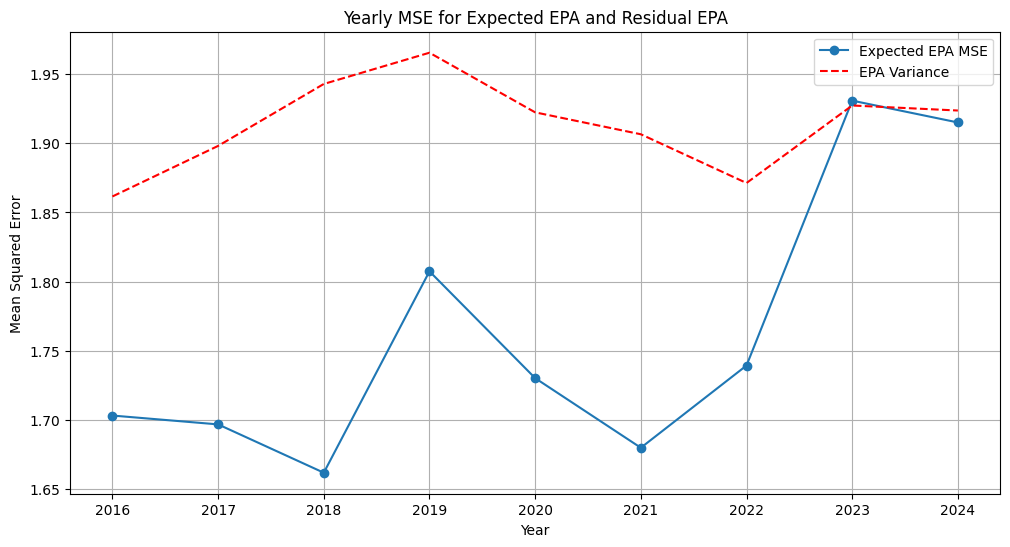

In [15]:
# Groupby year and calculate mean squared error for expected_epa
def mse_safe(y_true, y_pred):
    pair = pd.concat([y_true, y_pred], axis=1).dropna()
    return mean_squared_error(pair.iloc[:, 0], pair.iloc[:, 1]) if len(pair) else np.nan

yearly_mse = (
    df.groupby('year')
      .apply(lambda g: pd.Series({
          'expected_epa_mse': mse_safe(g['epa'], g['expected_epa'])
      }))
      .reset_index()
)

yearly_var = df.groupby('year').agg({'epa': 'var'}).reset_index()

# Plot yearly MSE
plt.figure(figsize=(12, 6))
plt.plot(yearly_mse['year'], yearly_mse['expected_epa_mse'], marker='o', label='Expected EPA MSE')
plt.plot(yearly_var['year'], yearly_var['epa'], color='r', linestyle='--', label='EPA Variance')
plt.title('Yearly MSE for Expected EPA and Residual EPA')
plt.xlabel('Year')
plt.ylabel('Mean Squared Error')
plt.legend()
plt.grid()
plt.show()

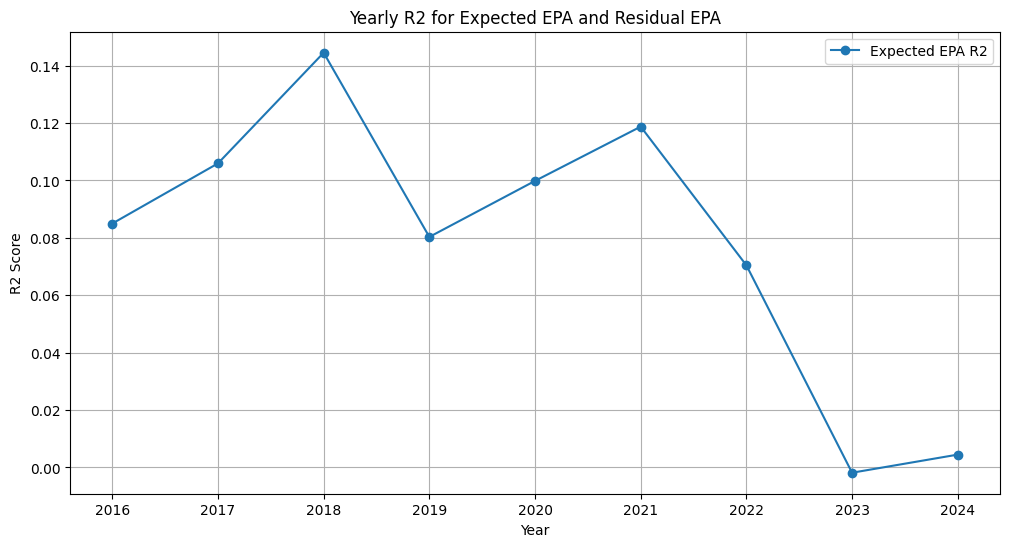

In [16]:
# Groupby year and calculate mean squared error for expected_epa
def rsquared_safe(y_true, y_pred):
    pair = pd.concat([y_true, y_pred], axis=1).dropna()
    return r2_score(pair.iloc[:, 0], pair.iloc[:, 1]) if len(pair) else np.nan

yearly_mse = (
    df.groupby('year')
      .apply(lambda g: pd.Series({
          'expected_epa_r2': rsquared_safe(g['epa'], g['expected_epa'])
      }))
      .reset_index()
)

yearly_var = df.groupby('year').agg({'epa': 'var'}).reset_index()

# Plot yearly MSE
plt.figure(figsize=(12, 6))
plt.plot(yearly_mse['year'], yearly_mse['expected_epa_r2'], marker='o', label='Expected EPA R2')
plt.title('Yearly R2 for Expected EPA and Residual EPA')
plt.xlabel('Year')
plt.ylabel('R2 Score')
plt.legend()
plt.grid()
plt.show()